# 1 - Data Exploration
**Project:** Cassava Leaf Disease Classification


## 1. Libraries and data

In [1]:
import os
import json
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = 224
CLASS_ORDER = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
SHORT = {0: "CBB", 1: "CBSD", 2: "CGM", 3: "CMD", 4: "Healthy"}
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

places = [
    os.environ.get("CASSAVA_DATA_DIR", ""),
    "/kaggle/input/competitions/cassava-leaf-disease-classification",
    "/kaggle/input/cassava-leaf-disease-classification",
    "/content/cassava-leaf-disease-classification",
    PROJECT_ROOT / "data" / "raw" / "cassava-leaf-disease-classification",
]
DATA_DIR = None
for place in places:
    if place and (Path(place) / "train.csv").exists():
        DATA_DIR = Path(place)
        break
if DATA_DIR is None:
    raise FileNotFoundError("Data not found. Read data/README.md")

IMG_DIR = DATA_DIR / "train_images"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
EDA_DIR = PROJECT_ROOT / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR.mkdir(parents=True, exist_ok=True)
print("Data folder:", DATA_DIR)


def open_rgb(image_id):
    return np.asarray(Image.open(IMG_DIR / image_id).convert("RGB"))


def show_grid(images, titles, cols=5, save_as=None):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.4))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    if save_as:
        plt.savefig(FIG_DIR / save_as, dpi=100, bbox_inches="tight")
    plt.show()

Data folder: /kaggle/input/competitions/cassava-leaf-disease-classification


## 2. Load the labels

In [2]:
df = pd.read_csv(DATA_DIR / "train.csv")
with open(DATA_DIR / "label_num_to_disease_map.json") as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

df["class_name"] = df["label"].map(label_map)
df["short_name"] = df["label"].map(SHORT)

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Repeated ids  :", df["image_id"].duplicated().sum())
assert df["image_id"].is_unique
assert df["label"].isin(SHORT).all()
df.head()

Shape: (21397, 4)
Missing values: 0
Repeated ids  : 0


,image_id,label,class_name,short_name
0,1000015157.jpg,0,Cassava Bacterial Blight (CBB),CBB
1,1000201771.jpg,3,Cassava Mosaic Disease (CMD),CMD
2,100042118.jpg,1,Cassava Brown Streak Disease (CBSD),CBSD
3,1000723321.jpg,1,Cassava Brown Streak Disease (CBSD),CBSD
4,1000812911.jpg,3,Cassava Mosaic Disease (CMD),CMD


## 3. Check every image

Missing files   : 0
Corrupt images  : 0
Repeated images : 0
Colour modes    : {'RGB': 21397}
Image sizes     : {'800x600': 21397}


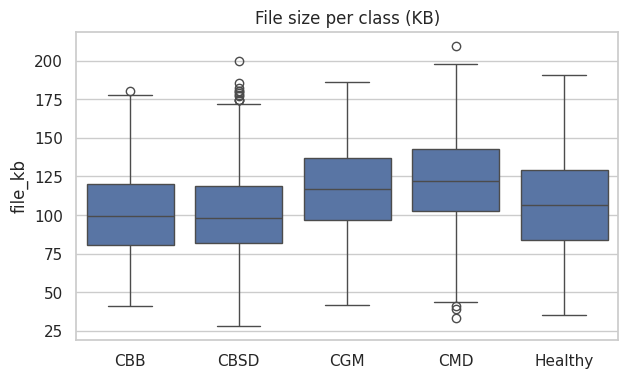

In [3]:
rows = []
for image_id in df["image_id"]:
    path = IMG_DIR / image_id
    row = {"image_id": image_id, "missing": not path.exists(), "corrupt": False}
    if not row["missing"]:
        try:
            im = Image.open(path)
            row["width"], row["height"], row["mode"] = im.width, im.height, im.mode
            arr = np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)
            grey = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]
            row["R"], row["G"], row["B"] = arr[:, :, 0].mean(), arr[:, :, 1].mean(), arr[:, :, 2].mean()
            row["brightness"] = grey.mean()
            row["contrast"] = grey.std()
            row["file_kb"] = path.stat().st_size / 1024
            row["md5"] = hashlib.md5(path.read_bytes()).hexdigest()
        except Exception:
            row["corrupt"] = True
    rows.append(row)

df = df.merge(pd.DataFrame(rows), on="image_id")
ok = df[~df["missing"] & ~df["corrupt"]]
sizes = ok["width"].astype(int).astype(str) + "x" + ok["height"].astype(int).astype(str)
dups = ok[ok["md5"].duplicated(keep=False)]

print("Missing files   :", df["missing"].sum())
print("Corrupt images  :", df["corrupt"].sum())
print("Repeated images :", len(dups))
print("Colour modes    :", ok["mode"].value_counts().to_dict())
print("Image sizes     :", sizes.value_counts().head(3).to_dict())

plt.figure(figsize=(7, 4))
sns.boxplot(data=ok, x="short_name", y="file_kb", order=CLASS_ORDER)
plt.title("File size per class (KB)")
plt.xlabel("")
plt.savefig(FIG_DIR / "eda_file_size.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Images per class

 label                          class_name short_name  count  percent
     0      Cassava Bacterial Blight (CBB)        CBB   1087     5.08
     1 Cassava Brown Streak Disease (CBSD)       CBSD   2189    10.23
     2          Cassava Green Mottle (CGM)        CGM   2386    11.15
     3        Cassava Mosaic Disease (CMD)        CMD  13158    61.49
     4                             Healthy    Healthy   2577    12.04

Imbalance ratio          : 12.1 (paper: 14.4)
Always-guess-CMD accuracy: 61.5%
Class weights            : {0: 3.9369, 1: 1.955, 2: 1.7935, 3: 0.3252, 4: 1.6606}


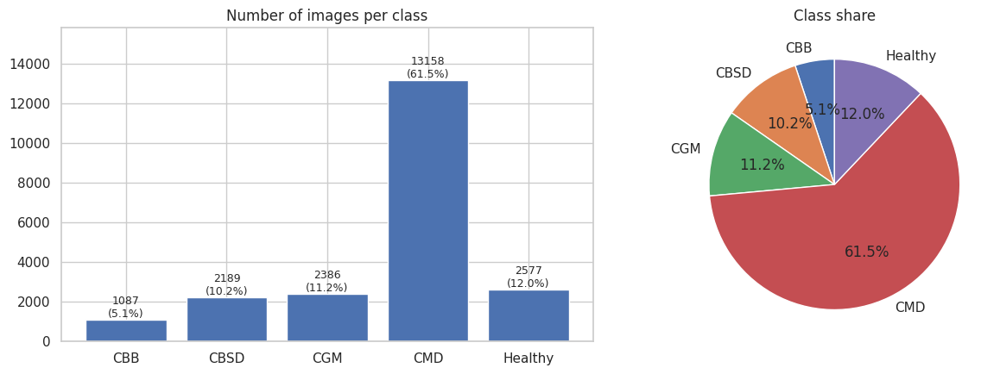

In [4]:
dist = df.groupby(["label", "class_name", "short_name"]).size().reset_index(name="count")
dist["percent"] = (100 * dist["count"] / len(df)).round(2)
imbalance_ratio = dist["count"].max() / dist["count"].min()
majority_acc = dist["count"].max() / len(df)
class_weights = {int(l): round(len(df) / (len(dist) * c), 4) for l, c in zip(dist["label"], dist["count"])}

print(dist.to_string(index=False))
print(f"\nImbalance ratio          : {imbalance_ratio:.1f} (paper: 14.4)")
print(f"Always-guess-CMD accuracy: {100 * majority_acc:.1f}%")
print("Class weights            :", class_weights)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar(dist["short_name"], dist["count"])
axes[0].bar_label(bars, labels=[f"{c}\n({p:.1f}%)" for c, p in zip(dist["count"], dist["percent"])], fontsize=9)
axes[0].set_ylim(0, dist["count"].max() * 1.2)
axes[0].set_title("Number of images per class")
axes[1].pie(dist["count"], labels=dist["short_name"], autopct="%1.1f%%", startangle=90)
axes[1].set_title("Class share")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_class_distribution.png", dpi=120)
plt.show()

## 5. Sample images

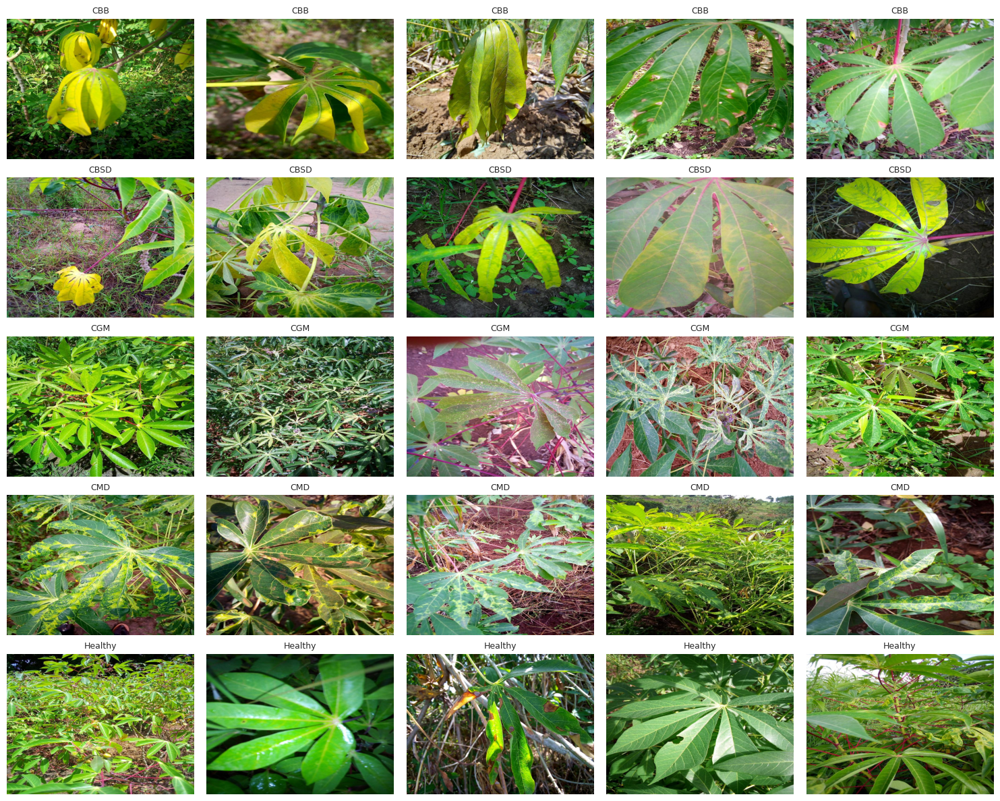

In [5]:
images, titles = [], []
for cls in CLASS_ORDER:
    picks = ok[ok["short_name"] == cls].sample(5, random_state=SEED)
    images += [open_rgb(i) for i in picks["image_id"]]
    titles += [cls] * 5
show_grid(images, titles, save_as="eda_sample_images.png")

## 6. Resize: stretch or crop?

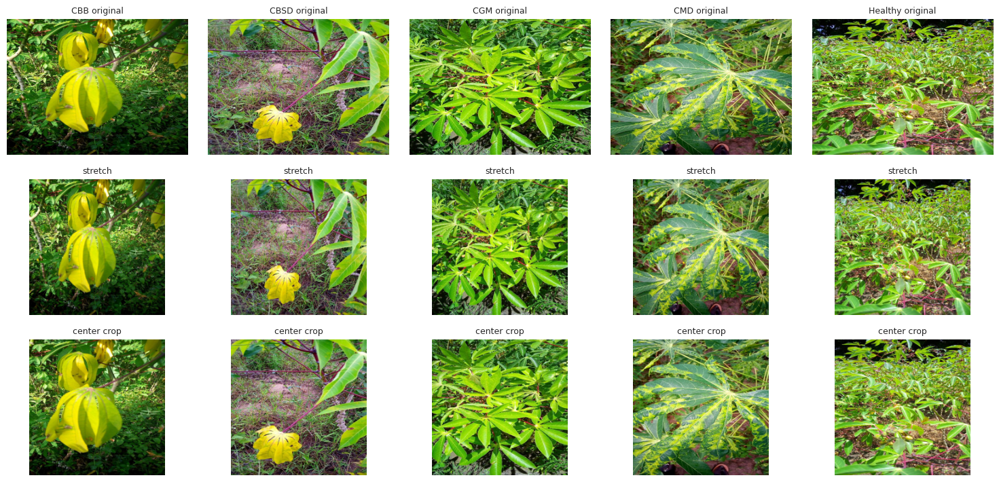

In [6]:
def stretch(img):
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)


def center_crop(img):
    h, w = img.shape[:2]
    s = min(h, w)
    top, left = (h - s) // 2, (w - s) // 2
    return stretch(img[top:top + s, left:left + s])


picks = [ok[ok["short_name"] == c].sample(1, random_state=SEED)["image_id"].iloc[0] for c in CLASS_ORDER]
originals = [open_rgb(i) for i in picks]
show_grid(originals + [stretch(i) for i in originals] + [center_crop(i) for i in originals],
          [f"{c} original" for c in CLASS_ORDER] + ["stretch"] * 5 + ["center crop"] * 5,
          save_as="eda_resize_vs_crop.png")

## 7. Brightness and contrast

Dark images (brightness < 80) : 2.5%
Low-contrast images (std < 35): 4.3%


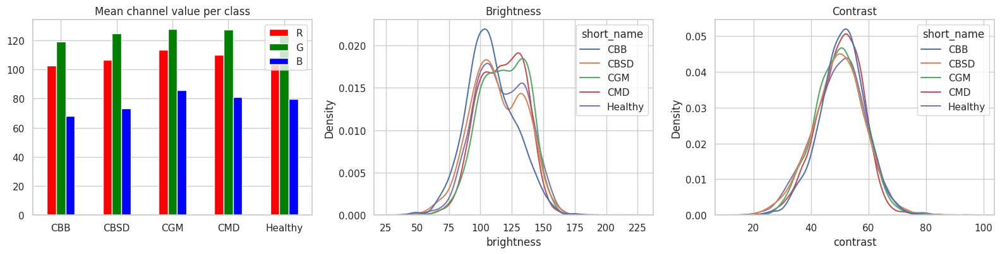

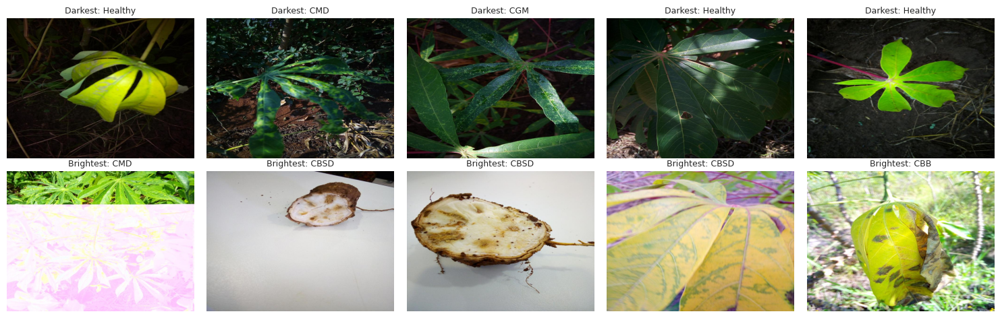

,R,G,B,brightness,contrast
short_name,,,,,
CBB,102.800003,119.000000,68.000000,108.300003,51.000000
CBSD,106.599998,124.900002,73.300003,113.599998,49.599998
CGM,113.500000,127.800003,85.800003,118.699997,49.799999
CMD,110.300003,127.300003,81.000000,117.000000,50.200001
Healthy,108.800003,126.800003,79.900002,116.099998,49.599998


In [7]:
pix_summary = ok.groupby("short_name")[["R", "G", "B", "brightness", "contrast"]].mean().loc[CLASS_ORDER].round(1)
df["dark"] = df["brightness"] < 80
df["low_contrast"] = df["contrast"] < 35
print(f"Dark images (brightness < 80) : {100 * df['dark'].mean():.1f}%")
print(f"Low-contrast images (std < 35): {100 * df['low_contrast'].mean():.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
pix_summary[["R", "G", "B"]].plot(kind="bar", color=["red", "green", "blue"], ax=axes[0], rot=0)
axes[0].set_title("Mean channel value per class")
axes[0].set_xlabel("")
sns.kdeplot(data=ok, x="brightness", hue="short_name", hue_order=CLASS_ORDER, common_norm=False, ax=axes[1])
axes[1].set_title("Brightness")
sns.kdeplot(data=ok, x="contrast", hue="short_name", hue_order=CLASS_ORDER, common_norm=False, ax=axes[2])
axes[2].set_title("Contrast")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_color_brightness.png", dpi=120)
plt.show()

darkest, brightest = ok.nsmallest(5, "brightness"), ok.nlargest(5, "brightness")
show_grid([open_rgb(i) for i in darkest["image_id"]] + [open_rgb(i) for i in brightest["image_id"]],
          [f"Darkest: {s}" for s in darkest["short_name"]] + [f"Brightest: {s}" for s in brightest["short_name"]],
          save_as="eda_dark_bright_examples.png")
pix_summary

## 8. What does CLAHE do to the images?

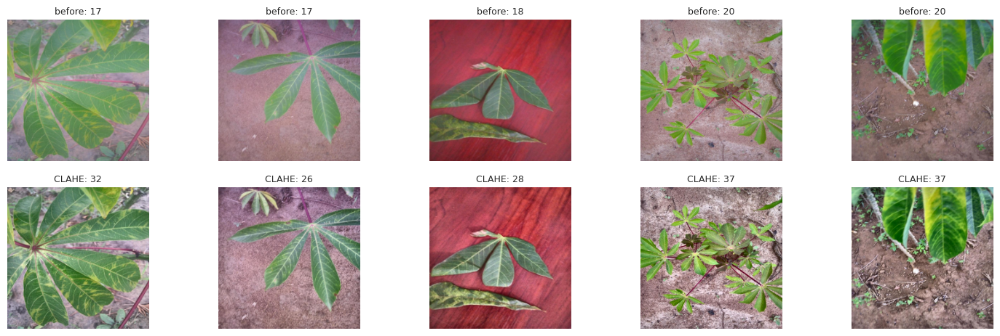

Low-contrast images: contrast 31.1 -> 48.5 after CLAHE


In [8]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def apply_clahe(img):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_RGB2LAB))
    return cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2RGB)


def contrast_of(img):
    return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).std()


flat = ok.nsmallest(5, "contrast")
before = [stretch(open_rgb(i)) for i in flat["image_id"]]
after = [apply_clahe(img) for img in before]
show_grid(before + after,
          [f"before: {contrast_of(img):.0f}" for img in before] + [f"CLAHE: {contrast_of(img):.0f}" for img in after],
          save_as="eda_clahe_effect.png")

sample = ok[ok["contrast"] < 35].sample(min(200, (ok["contrast"] < 35).sum()), random_state=SEED)
before_c = [contrast_of(stretch(open_rgb(i))) for i in sample["image_id"]]
after_c = [contrast_of(apply_clahe(stretch(open_rgb(i)))) for i in sample["image_id"]]
clahe_before, clahe_after = float(np.mean(before_c)), float(np.mean(after_c))
print(f"Low-contrast images: contrast {clahe_before:.1f} -> {clahe_after:.1f} after CLAHE")

## 9. Random or stratified split?

In [9]:
results = []
for seed in range(20):
    _, test_random = train_test_split(df, test_size=0.2, random_state=seed)
    _, test_strat = train_test_split(df, test_size=0.2, random_state=seed, stratify=df["label"])
    results.append({"random": 100 * (test_random["short_name"] == "CBB").mean(),
                    "stratified": 100 * (test_strat["short_name"] == "CBB").mean()})
results = pd.DataFrame(results)

print(f"CBB share in all data: {100 * (df['short_name'] == 'CBB').mean():.2f}%")
print("CBB share in the test set over 20 seeds:")
print(results.agg(["min", "max"]).round(2))

split = dist[["short_name", "count"]].copy()
split["train"] = (split["count"] * 0.6).round().astype(int)
split["val"] = (split["count"] * 0.2).round().astype(int)
split["test"] = split["count"] - split["train"] - split["val"]
split.loc["Total"] = ["Total", split["count"].sum(), split["train"].sum(), split["val"].sum(), split["test"].sum()]
split

CBB share in all data: 5.08%
CBB share in the test set over 20 seeds:
     random  stratified
min    4.74        5.07
max    5.68        5.07


,short_name,count,train,val,test
0,CBB,1087,652,217,218
1,CBSD,2189,1313,438,438
2,CGM,2386,1432,477,477
3,CMD,13158,7895,2632,2631
4,Healthy,2577,1546,515,516
Total,Total,21397,12838,4279,4280


## 10. Save the results

In [10]:
dist.to_csv(EDA_DIR / "class_distribution.csv", index=False)
split.to_csv(EDA_DIR / "expected_split_sizes.csv", index=False)
pix_summary.to_csv(EDA_DIR / "color_brightness_by_class.csv")
df.drop(columns="md5").to_csv(EDA_DIR / "image_metadata.csv", index=False)

summary = {
    "n_images": len(df),
    "class_counts": dict(zip(dist["short_name"], dist["count"].tolist())),
    "imbalance_ratio": round(float(imbalance_ratio), 2),
    "missing_corrupt_repeated": [int(df["missing"].sum()), int(df["corrupt"].sum()), len(dups)],
    "dark_pct": round(100 * float(df["dark"].mean()), 2),
    "low_contrast_pct": round(100 * float(df["low_contrast"].mean()), 2),
    "class_weights": class_weights,
}
with open(EDA_DIR / "eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "n_images": 21397,
  "class_counts": {
    "CBB": 1087,
    "CBSD": 2189,
    "CGM": 2386,
    "CMD": 13158,
    "Healthy": 2577
  },
  "imbalance_ratio": 12.1,
  "missing_corrupt_repeated": [
    0,
    0,
    0
  ],
  "dark_pct": 2.46,
  "low_contrast_pct": 4.3,
  "class_weights": {
    "0": 3.9369,
    "1": 1.955,
    "2": 1.7935,
    "3": 0.3252,
    "4": 1.6606
  }
}


## 11. What we found
1. **Clean data:** 21,397 images, all 800x600 RGB. No missing, corrupt or repeated images, so nothing is removed.
2. **Unequal classes:** CMD has 13,158 images (61.5%) and CBB only 1,087 (5.1%), a ratio of 12.1 (paper: 14.4).
   Always guessing CMD already gives 61.5% accuracy, so we also report macro F1 and the confusion matrix and use
   class weights (CBB 3.94, CMD 0.33).
3. **Resize:** we stretch to 224x224 instead of cropping, so disease spots near the edges are not cut off.
4. **Light:** 2.5% of the images are dark and 4.3% are low-contrast. CLAHE on the L channel raises the contrast of
   low-contrast images from 31.1 to 48.5 without changing the colours. Whether it improves the model will be tested
   in training (with and without CLAHE).
5. **Split:** over 20 seeds, a random split puts between 4.74% and 5.68% CBB in the test set; a stratified split
   always gives 5.07%. So we use a stratified 60/20/20 split (12,838 / 4,279 / 4,280 images).
6. **Harder than the paper:** our photos are taken in farms (shadows, many leaves), not in a lab, so we expect
   less than 99.3% accuracy.